In [23]:
import numpy as np
import pandas as pd
import time

In [24]:
df = pd.read_csv('016-social-network-ads.csv')

In [25]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [26]:
df = df[
    ['Age' , 'EstimatedSalary', 'Purchased']
]

In [27]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [28]:
X = df.iloc[ :, 0:2]
y = df.iloc[ :, -1]

In [29]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [30]:
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    0
399    1
Name: Purchased, Length: 400, dtype: int64

In [31]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [32]:
X_scaled.shape

(400, 2)

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

In [34]:
X_train.shape

(320, 2)

In [35]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [36]:
model = Sequential()

model.add(Dense(10, activation = 'relu', input_dim = 2))
model.add(Dense(10, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

d:\Rat_Race\AI-ML\env\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [37]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

### **Batch GD**

In [38]:
model.compile(
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

start = time.time()
history = model.fit(
    X_train,
    y_train,
    epochs = 10, 
    batch_size = 320    
    # 320 total number of rows in a dataset that means it is referred as batch GD
    # if batch_size = 1 then it refers the to the stochastic GD
)
print(f"Time: {time.time() - start}")

Epoch 1/10


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.3469 - loss: 6181.6538
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3469 - loss: 4824.2007
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3469 - loss: 3839.6772
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3469 - loss: 3015.1675
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3469 - loss: 2283.0024
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3469 - loss: 1611.7683
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3469 - loss: 983.9518
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3469 - loss: 388.6576
Epoch 9/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6531 - loss: 137.6564
Epoch 10/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3469 - loss: 251.8375
Time: 0.4401404857635498


### **Stochastic GD**

In [39]:
model.compile(
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

start = time.time()
history = model.fit(
    X_train,
    y_train,
    epochs = 10, 
    batch_size = 1    
)
print(f"Time: {time.time() - start}")

Epoch 1/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 505us/step - accuracy: 0.5281 - loss: 268.1757
Epoch 2/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 510us/step - accuracy: 0.5500 - loss: 258.7458
Epoch 3/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step - accuracy: 0.5469 - loss: 255.5268
Epoch 4/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - accuracy: 0.5594 - loss: 247.6366
Epoch 5/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step - accuracy: 0.5688 - loss: 247.9812
Epoch 6/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 503us/step - accuracy: 0.5562 - loss: 243.5938
Epoch 7/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step - accuracy: 0.5219 - loss: 252.7043
Epoch 8/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 503us/step - accuracy: 0.5562 - loss: 241.0312
Epoch 9/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 509us/step - accuracy: 0.5625 - loss: 240.0349
Epoch 10/10
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 510us/step - accuracy: 0.5656 - loss: 236.7124
Time: 2.0701515674591064


### **Convergence Efficiency**

#### Batch GD

In [40]:
import matplotlib.pyplot as plt

In [41]:
model.compile(
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

start = time.time()
history = model.fit(
    X_train,
    y_train,
    epochs = 500, 
    batch_size = 400,     # X_scaled
    validation_split = 0.2
)
print(f"Time: {time.time() - start}")

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.6367 - loss: 233.8142 - val_accuracy: 0.2812 - val_loss: 1110.1509
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3633 - loss: 893.9586 - val_accuracy: 0.7188 - val_loss: 27.2991
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6367 - loss: 32.9514 - val_accuracy: 0.2812 - val_loss: 773.5396
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3633 - loss: 622.4222 - val_accuracy: 0.7188 - val_loss: 49.8169
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6367 - loss: 58.2156 - val_accuracy: 0.2812 - val_loss: 572.1074
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.3633 - loss: 459.9310 - val_accuracy: 0.7188 - val_loss: 95.3745
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6367 - loss: 109.3309 - val_accuracy: 0.2812 - val_loss: 415.5857
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3633 - loss: 333.6685 - val_a

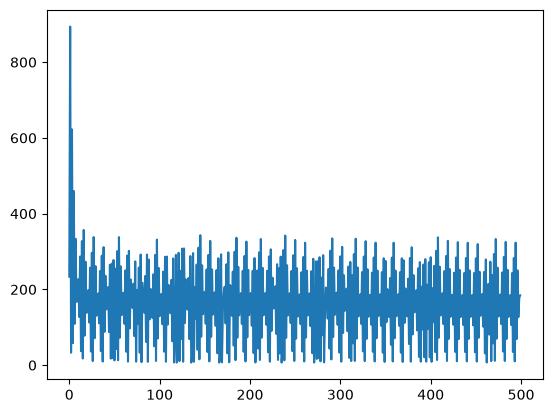

In [42]:
plt.plot(history.history['loss'])

#### Stochastic

In [43]:
model.compile(
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

start = time.time()
history = model.fit(
    X_train,
    y_train,
    epochs = 500, 
    batch_size = 1,     
    validation_split = 0.2
)
print(f"Time: {time.time() - start}")

Epoch 1/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step - accuracy: 0.5078 - loss: 243.7712 - val_accuracy: 0.7188 - val_loss: 286.8535
Epoch 2/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 713us/step - accuracy: 0.4844 - loss: 234.7324 - val_accuracy: 0.7188 - val_loss: 84.7242
Epoch 3/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 708us/step - accuracy: 0.4922 - loss: 235.8253 - val_accuracy: 0.7188 - val_loss: 132.8150
Epoch 4/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 735us/step - accuracy: 0.4922 - loss: 235.6015 - val_accuracy: 0.7188 - val_loss: 83.3066
Epoch 5/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step - accuracy: 0.4844 - loss: 229.7834 - val_accuracy: 0.7188 - val_loss: 74.2964
Epoch 6/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step - accuracy: 0.5039 - loss: 217.6774 - val_accuracy: 0.7188 - val_loss: 39.4391
Epoch 7/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step - accuracy: 0.4922 - loss: 226.6487 - val_accuracy: 0.7188 - val_loss: 57.6207
Epoch 8/500
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 731us/step - acc

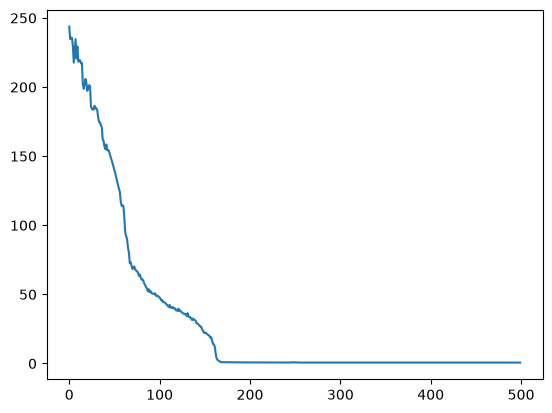

In [44]:
plt.plot(history.history['loss'])